# Week Ten - Document Classification
**Spam vs ham classification using the UCI Spambase data.**

**Author: Tanvir Raju**

Nov 16, 2026

## Approach
The goal is to classify emails as spam or ham using labeled examples. The Spambase data has 4,601 emails, each described by 57 numeric features: the frequency of 48 chosen words, the frequency of 6 characters, and 3 measures of capital letter runs. The label marks each email as spam (1) or ham (0). The data was split 75/25 into training and test sets (stratified so both keep the same spam share), and three classifiers were compared: Naive Bayes, Logistic Regression and Random Forest.

## Load data

In [1]:
import io
import os
import re
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

ZIP_PATH = "spambase.zip"
URL = "https://archive.ics.uci.edu/static/public/94/spambase.zip"

if not os.path.exists(ZIP_PATH):
    urllib.request.urlretrieve(URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as z:
    names_txt = z.read("spambase.names").decode()
    data = z.read("spambase.data").decode()

cols = re.findall(r"^(\S+?):\s+continuous\.", names_txt, flags=re.M) + ["spam"]

df = pd.read_csv(io.StringIO(data), header=None, names=cols)
df.shape

(4601, 58)

## Explore

In [2]:
df["spam"].value_counts(normalize=True)

,proportion
spam,
0,0.605955
1,0.394045


In [3]:
top = df.drop(columns="spam").groupby(df["spam"]).mean().T
top["diff"] = top[1] - top[0]
top.sort_values("diff", ascending=False).head(10)

spam,0,1,diff
capital_run_length_total,161.470947,470.619415,309.148468
capital_run_length_longest,18.214491,104.393271,86.178780
capital_run_length_average,2.377301,9.519165,7.141864
word_freq_you,1.270341,2.264539,0.994199
word_freq_your,0.438702,1.380370,0.941668
word_freq_free,0.073587,0.518362,0.444775
char_freq_!,0.109984,0.513713,0.403729
word_freq_our,0.181040,0.513955,0.332915
word_freq_remove,0.009383,0.275405,0.266022
word_freq_000,0.007088,0.247055,0.239967


About 39% of the emails are spam, so the classes are moderately imbalanced and accuracy alone is not enough. Spam emails have much longer runs of capital letters and use words such as "you", "your", "free", "remove" and "000" and the "!" character far more often than ham.

## Train and test split

In [4]:
X = df.drop(columns="spam")
y = df["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=605)

## Models

In [5]:
models = {
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=605, n_jobs=-1),
}

rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1
Model,,,,
Naive Bayes,0.8401,0.7243,0.9604,0.8258
Logistic Regression,0.9235,0.9159,0.8877,0.9016
Random Forest,0.9522,0.9404,0.9383,0.9394


Random Forest performed best on every metric, with 95.2% accuracy and an F1 of 0.939. Logistic Regression was next at 92.4% accuracy. Naive Bayes had the highest recall (0.960) but the lowest precision (0.724), so it catches almost all spam at the cost of flagging many legitimate emails. This is expected since it assumes the features are independent and treats the skewed word frequencies as Gaussian.

## Confusion matrices

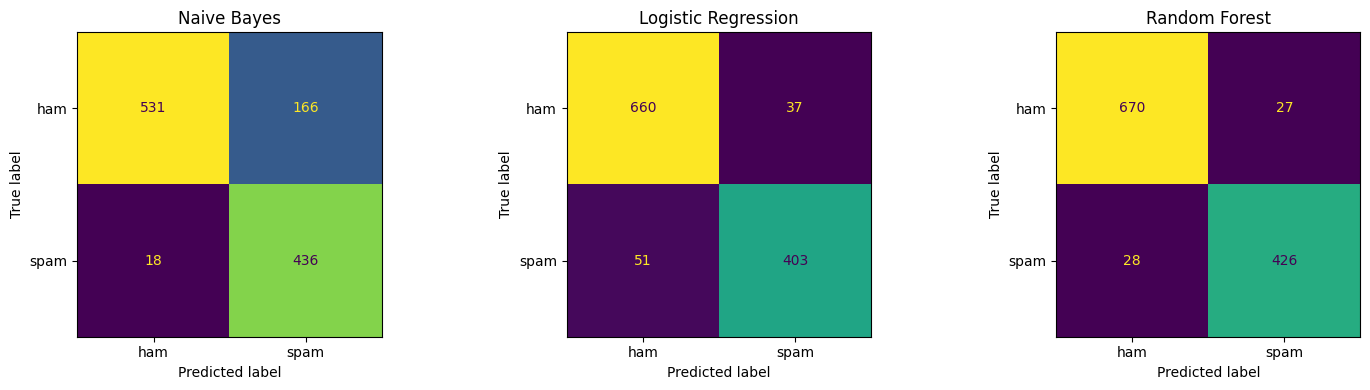

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p),
                           display_labels=["ham", "spam"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

The test set has 697 ham and 454 spam emails. Naive Bayes wrongly flagged 166 ham emails as spam and missed 18 spam emails. Logistic Regression made 37 false positives and 51 false negatives. Random Forest was the most balanced with 27 false positives and 28 false negatives. False positives are the costlier error here since a real email lands in the spam folder.

## Cross validation

In [7]:
cv = pd.DataFrame({
    name: cross_val_score(m, X, y, cv=5, scoring="f1", n_jobs=-1)
    for name, m in models.items()
})
cv.agg(["mean", "std"]).round(4)

,Naive Bayes,Logistic Regression,Random Forest
mean,0.8145,0.8881,0.9134
std,0.0624,0.0478,0.0636


The 5-fold cross validation F1 scores keep the same ranking (Random Forest 0.913, Logistic Regression 0.888, Naive Bayes 0.815), so the test split result is not a lucky draw. The scores are lower than on the single split and the standard deviation is around 0.05 to 0.06, which suggests the folds vary in difficulty. The spread overlaps for the top two models, so the gap between Random Forest and Logistic Regression is real but modest.

## Important features

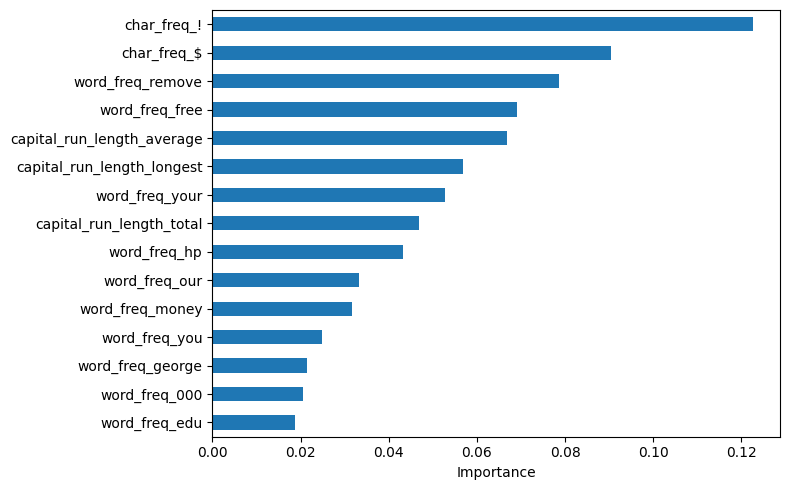

In [8]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(15)
imp.plot.barh(figsize=(8, 5))
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

The most important features are the "!" and "$" character frequencies, the word "remove" and "free", and the capital run length measures. These match the patterns seen in the exploration step. The word "hp" also ranks highly, but it points toward ham, since the emails were collected from a Hewlett-Packard mailbox. Features like "hp" and "george" are specific to this dataset, so a model trained on it may not transfer well to other inboxes without retraining.

## Classify a new document

In [9]:
new = X_test.iloc[[0]]
print("Predicted:", "spam" if rf.predict(new)[0] == 1 else "ham")
print("Actual:", "spam" if y_test.iloc[0] == 1 else "ham")

Predicted: ham
Actual: ham


The model correctly classified the first held-out email as ham. Any new email can be classified the same way once it is converted to the same 57 features.

## Conclusion
Random Forest was the best classifier for this task, reaching about 95% accuracy and an F1 of 0.94 on unseen emails, with cross validation supporting the same ranking. Simple signals such as exclamation marks, dollar signs, capital letter runs and words like "free" and "remove" are enough to separate spam from ham reliably. A possible next step is to build features from raw email text and test on a different inbox to check how well the model generalizes.